# 01 — Claim frequency and severity

This notebook explores two inputs to the annual loss model.

- **Claim frequency** describes how often claims occur. We measure it in
  expected claims per policy-year. One policy-year is one policy covered
  for one year.
- **Claim severity** is the amount paid on one claim, measured in CAD.

The inputs are illustrative. The baseline assumes 1,000 policy-years and
0.05 expected claims per policy-year, giving 50 expected claims in one year.

In [7]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

from src.simulation import BASELINE, sample_claim_amounts, sample_claim_counts

Expected annual claim count: 50.00
Simulated mean claim count:  49.99


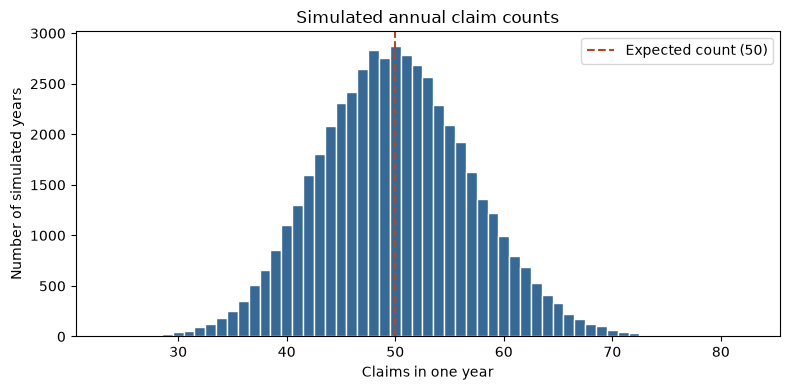

In [6]:
expected_claims = BASELINE["exposure"] * BASELINE["frequency"]
rng = np.random.default_rng(BASELINE["seed"])

claim_counts = sample_claim_counts(
    expected_claims,
    BASELINE["n_years"],
    rng,
)

print(f"Expected annual claim count: {expected_claims:.2f}")
print(f"Simulated mean claim count:  {claim_counts.mean():.2f}")

bins = np.arange(claim_counts.min() - 0.5, claim_counts.max() + 1.5)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(claim_counts, bins=bins, color="#376996", edgecolor="white")
ax.axvline(
    expected_claims,
    color="#b34724",
    linestyle="--",
    label=f"Expected count ({expected_claims:.0f})",
)
ax.set(
    title="Simulated annual claim counts",
    xlabel="Claims in one year",
    ylabel="Number of simulated years",
)
ax.legend()
fig.tight_layout()
plt.show()

Assumed mean claim:    CAD 5,000
Simulated mean claim:  CAD 5,023
Simulated median:      CAD 2,758
Assumed std. dev.:     CAD 7,500
Simulated std. dev.:   CAD 8,053


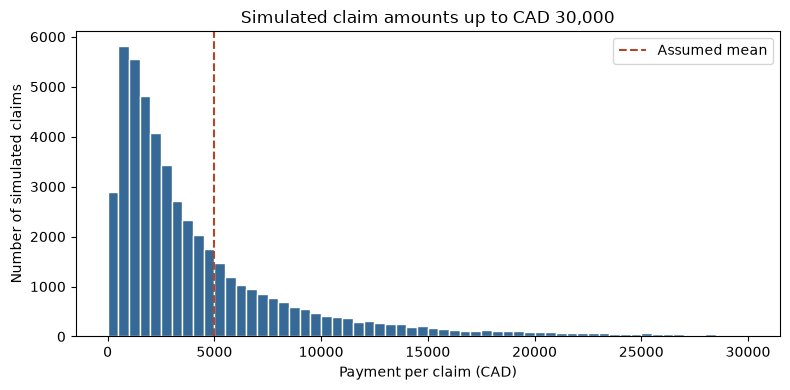

In [8]:
severity_mean = BASELINE["severity_mean"]
severity_std_dev = BASELINE["severity_std_dev"]

claim_amounts = sample_claim_amounts(
    mean=severity_mean,
    std_dev=severity_std_dev,
    n_claims=50_000,
    rng=np.random.default_rng(BASELINE["seed"]),
)

print(f"Assumed mean claim:    CAD {severity_mean:,.0f}")
print(f"Simulated mean claim:  CAD {claim_amounts.mean():,.0f}")
print(f"Simulated median:      CAD {np.median(claim_amounts):,.0f}")
print(f"Assumed std. dev.:     CAD {severity_std_dev:,.0f}")
print(f"Simulated std. dev.:   CAD {claim_amounts.std(ddof=1):,.0f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(
    claim_amounts,
    bins=60,
    range=(0, 30_000),
    color="#376996",
    edgecolor="white",
)
ax.axvline(
    severity_mean,
    color="#b34724",
    linestyle="--",
    label="Assumed mean",
)
ax.set(
    title="Simulated claim amounts up to CAD 30,000",
    xlabel="Payment per claim (CAD)",
    ylabel="Number of simulated claims",
)
ax.legend()
fig.tight_layout()
plt.show()

The claim-size distribution is right-skewed. The median is below the
mean because occasional large payments pull the average upward.

The next notebook combines the annual claim count and the payments on
those claims to estimate total losses for the portfolio in one year.